# Analyzing Economic Indicators with the FRED API



In [1]:
# import relevant packages 
import pandas as pd
from fredapi import Fred
import matplotlib.pyplot as plt

## Problem 1

Ensure access to the FRED API. Apply your individual `API key`.

In [2]:
from fredapi import Fred
import os 
api_key = os.getenv('fred_key')
fred = Fred(api_key=api_key)

**Tolkning:** We connected to the FRED API by storing our personal API key as an environment variable (fred_key) on the computer, rather than writing it directly in the code. This is standard practice for keeping sensitive credentials out of shared code files. The Fred() object (named 'fred') now gives us access to download economic data series directly into Python.

## Problem 2

Retrieve data for the three economic indicators starting from 2001-01-01: 

* GDP (Gross Domestic Product): Series ID `GDP`
* Unemployment Rate: Series ID `UNRATE`
* Consumer Price Index (CPI) for All Urban Consumers: Series ID `CPIAUCSL`

What do you note about the data-frequency?

In [3]:
# hent tre datasæt fra FRED, fra år 2001 og frem
gdp = fred.get_series('GDP', observation_start='2001-01-01')
unrate = fred.get_series('UNRATE', observation_start='2001-01-01')
cpi = fred.get_series('CPIAUCSL', observation_start='2001-01-01')

# kig på de første par rækker af hver
print(gdp.head())
print(unrate.head())
print(cpi.head())

2001-01-01    10470.231
2001-04-01    10599.000
2001-07-01    10598.020
2001-10-01    10660.465
2002-01-01    10783.500
dtype: float64
2001-01-01    4.2
2001-02-01    4.2
2001-03-01    4.3
2001-04-01    4.4
2001-05-01    4.3
dtype: float64
2001-01-01    175.6
2001-02-01    176.0
2001-03-01    176.1
2001-04-01    176.4
2001-05-01    177.3
dtype: float64


**Tolkning:**
 GDP data comes only 4 times per year (quarterly), while unemployment (UNRATE) and inflation (CPI) data come 12 times per year (monthly). This means the three series have different "frequencies" — something we need to be careful about later if we want to compare or plot them together, since they don't update at the same pace.

## Problem 3

Plot the three variables using line-plots.  

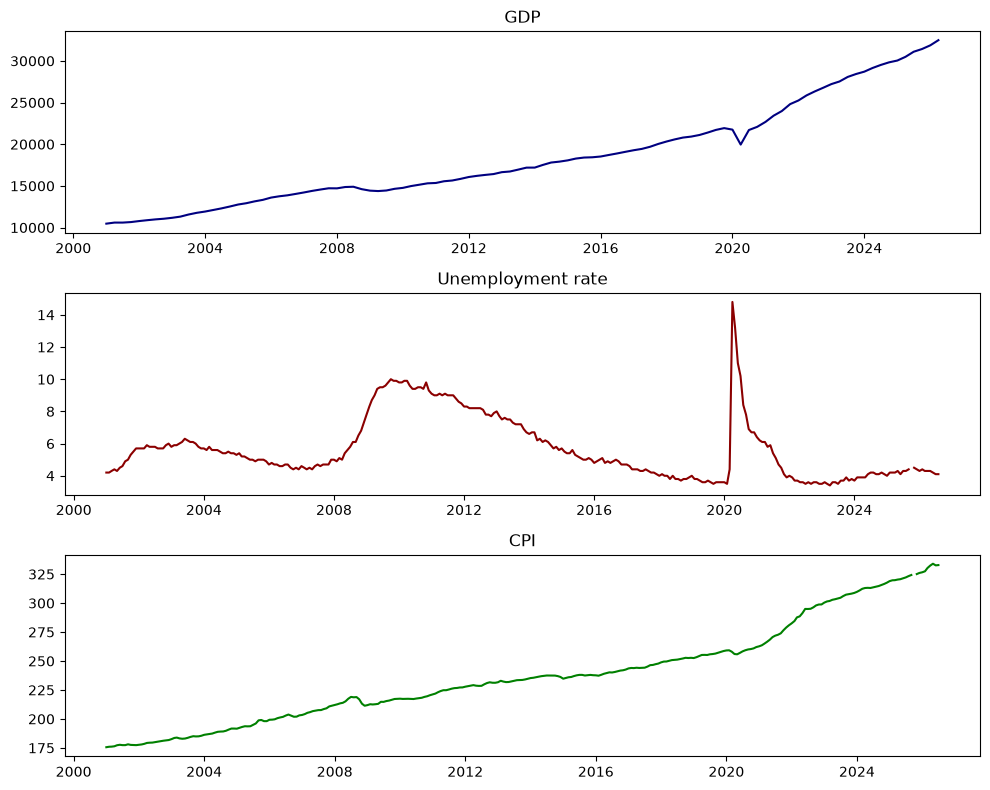

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

axes[0].plot(gdp, color="navy")
axes[0].set_title("GDP")

axes[1].plot(unrate, color="darkred")
axes[1].set_title("Unemployment rate")

axes[2].plot(cpi, color="green")
axes[2].set_title("CPI")

plt.tight_layout()
plt.show()

**Tolkning:** The three plots show very different patterns. GDP and CPI both trend steadily upward over time (economic growth and inflation are normal, ongoing processes). Unemployment, on the other hand, moves up and down with clear spikes during recessions (like 2008-2009 and 2020) - showing that unemployment reacts sharply to economic shocks in a way GDP and CPI don't.

## Problem 4

Calculate the quarterly growth rate for GDP and the annual inflation rate from the CPI data. Plot the growth rates using a line-plot. 

/var/folders/mf/48f1y7ns2zxbjrj3_b_g3jpr0000gn/T/ipykernel_3566/198393250.py:5: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  cpi_inflation = cpi.pct_change(periods=12) * 100


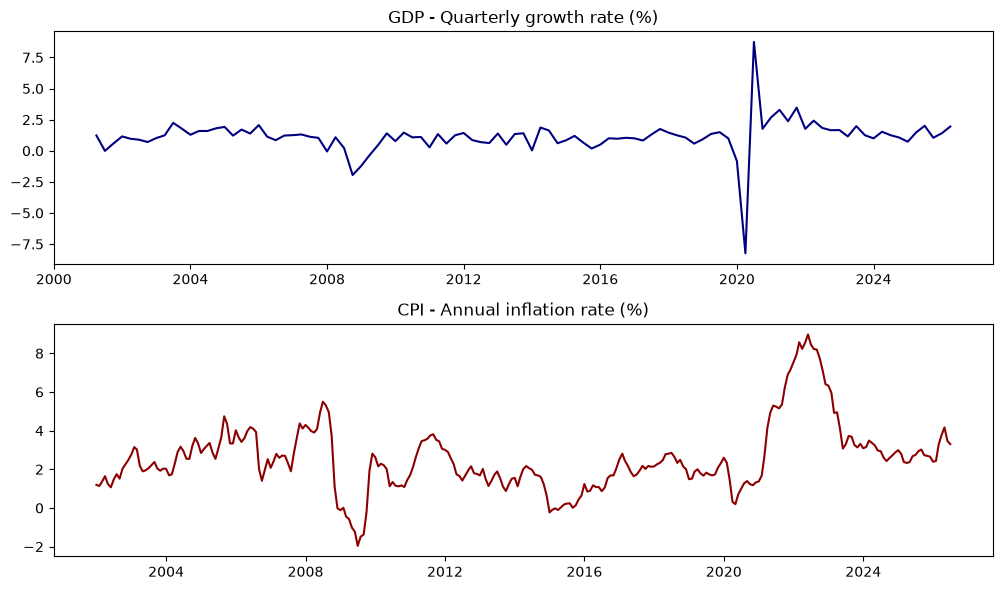

In [5]:
# GDP kvartalsvis vækstrate (procentvis ændring fra forrige værdi)
gdp_growth = gdp.pct_change() * 100

# CPI årlig inflation (procentvis ændring ift. 12 måneder siden)
cpi_inflation = cpi.pct_change(periods=12) * 100

# plot begge
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].plot(gdp_growth, color="navy")
axes[0].set_title("GDP - Quarterly growth rate (%)")

axes[1].plot(cpi_inflation, color="darkred")
axes[1].set_title("CPI - Annual inflation rate (%)")

plt.tight_layout()
plt.show()

**Tolkning:** GDP quarterly growth is normally small and positive (around 1-2%), but drops sharply negative during the 2020 COVID recession. CPI annual inflation is usually stable around 2-3%, but spikes dramatically to around 8-9% in 2022 - reflecting the well-known post-pandemic inflation surge. Converting raw levels into growth/inflation rates makes it much easier to spot these economic shocks compared to looking at the raw GDP or CPI plots.